# Episode 02 — The CRS mistakes everyone makes

**Course:** Geospatial Data Science with Python

Series 1: Spatial Data in Python


### Data

**Unfallatlas 2018 — Berlin road accidents** (13,652 georeferenced crashes), published by the
Statistical Offices of the Federation and the States under *Datenlizenz Deutschland —
Namensnennung 2.0* (dl-de/by-2-0). Boundaries: ALKIS Berlin *Ortsteile* (97 polygons).


## Setup


**install Libs**

In [ ]:
import importlib, subprocess, sys
for mod, pkg in [("geopandas", "geopandas"), ("mapclassify", "mapclassify")]:
    if importlib.util.find_spec(mod) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

**Load Data**

In [ ]:
import os, urllib.request

TS = "https://raw.githubusercontent.com/tagesspiegel/Unfallatlas-Berlin-2018/master/"
URLS = {
    "accidents_berlin_2018.geojson": TS + "unfaelle_berlin_2018.geo.json",
    "berlin_ortsteile.geojson":
        "https://raw.githubusercontent.com/codeforgermany/click_that_hood/main/public/data/berlin.geojson",
}

def data_path(name, folder="data"):
    """Return a local path to a course dataset, downloading it only if needed."""
    for candidate in (os.path.join(folder, name), os.path.join("..", folder, name), name):
        if os.path.exists(candidate):
            return candidate
    os.makedirs(folder, exist_ok=True)
    target = os.path.join(folder, name)
    print("downloading", name, "...")
    urllib.request.urlretrieve(URLS[name], target)
    return target

print("setup done")


setup done


In [ ]:
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt

acc = gpd.read_file(data_path("accidents_berlin_2018.geojson"))
ot = gpd.read_file(data_path("berlin_ortsteile.geojson"))[["name", "geometry"]] \
        .rename(columns={"name": "ortsteil"})

print(len(acc), "accidents |", len(ot), "neighbourhoods")


13652 accidents | 97 neighbourhoods


---
## **What area does Berlin cover?**


In [ ]:
for epsg, label in [(4326, "WGS 84      (degrees)"),
                    (3857, "Web Mercator (metres)"),
                    (25833, "UTM 33N      (metres)")]:
    area = ot.to_crs(epsg).geometry.area.sum()
    unit = "deg²" if epsg == 4326 else "km²"
    value = area if epsg == 4326 else area / 1e6
    print(f"EPSG:{epsg:<6} {label:24s} {value:12,.3f} {unit}")


EPSG:4326   WGS 84      (degrees)           0.118 deg²
EPSG:3857   Web Mercator (metres)       2,400.614 km²
EPSG:25833  UTM 33N      (metres)         890.666 km²


/var/folders/pb/3hs3_9mn29v77k5hgm1804yr0000gn/T/ipykernel_8608/2439468365.py:4: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  area = ot.to_crs(epsg).geometry.area.sum()


## Reading a CRS

In [ ]:
crs = acc.crs
print("name       :", crs.name)
print("EPSG code  :", crs.to_epsg())
print("unit       :", crs.axis_info[0].unit_name)
print("projected? :", crs.is_projected)

print("area of use:", crs.area_of_use.name)

name       : WGS 84
EPSG code  : 4326
unit       : degree
projected? : False
area of use: World.


## Mistake 1: measuring in degrees

A degree is not a distance.


In [ ]:
p, q = acc.geometry.iloc[0], acc.geometry.iloc[1]
print("distance in degrees:", round(p.distance(q), 6), "  <- a number, not a distance")

acc_m = acc.to_crs(25833)
pm, qm = acc_m.geometry.iloc[0], acc_m.geometry.iloc[1]
print("distance in metres :", round(pm.distance(qm), 1), "m")


distance in degrees: 0.198193   <- a number, not a distance
distance in metres : 14928.2 m


In [ ]:
# how long is one degree, here?

lat = 52.52
print(f"1° latitude  at Berlin: {111_320/1000:6.1f} km")
print(f"1° longitude at Berlin: {111_320*np.cos(np.radians(lat))/1000:6.1f} km")
print(f"ratio: {1/np.cos(np.radians(lat)):.2f}  <- east-west and north-south are not the same unit")


1° latitude  at Berlin:  111.3 km
1° longitude at Berlin:   67.7 km
ratio: 1.64  <- east-west and north-south are not the same unit


**The rule:** project to metres before `.area`, `.length`, `.distance` or `.buffer`.
GeoPandas will not stop you — it happily returns a number.

## Mistake 2: `set_crs` vs. `to_crs`

- `set_crs()` **relabels** — the coordinates stay exactly as they are.
- `to_crs()` **reprojects** — the coordinates change.


In [ ]:
projected = acc.to_crs(25833)                           # correct
relabelled = projected.set_crs(4326, allow_override=True)   # a lie

print("to_crs  -> x =", round(projected.geometry.x.iloc[0], 1),
      "| declared CRS:", projected.crs.to_epsg())

print("set_crs -> x =", round(relabelled.geometry.x.iloc[0], 1),
      "| declared CRS:", relabelled.crs.to_epsg())
print("\nThe coordinates are identical. Only the label changed.")

to_crs  -> x = 396514.6 | declared CRS: 25833
set_crs -> x = 396514.6 | declared CRS: 4326

The coordinates are identical. Only the label changed.


In [ ]:

print("claimed longitude:", round(relabelled.geometry.x.iloc[0], 1), "degrees")
print("valid range      : -180 to 180")


claimed longitude: 396514.6 degrees
valid range      : -180 to 180


**How to catch it**❓

In [ ]:
print(acc.crs)

EPSG:4326


## Mistake 3: mixing CRS between layers


In [ ]:
import warnings

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    bad = gpd.sjoin(acc.to_crs(25833), ot, how="left", predicate="within")   # 25833 vs 4326
    for w in caught:
        print("WARNING:", str(w.message).split("\n")[0])

good = gpd.sjoin(acc.to_crs(25833), ot.to_crs(25833), how="left", predicate="within")

print()
print(f"mismatched CRS -> {bad['ortsteil'].notna().sum():>6,} matches out of {len(bad):,}")
print(f"matching CRS   -> {good['ortsteil'].notna().sum():>6,} matches out of {len(good):,}")



mismatched CRS ->      0 matches out of 13,652
matching CRS   -> 13,649 matches out of 13,652


In [ ]:
bad.head()

,UMONAT,USTUNDE,UKATEGORIE,ULICHTVERH,IstRad,IstPKW,IstFuss,IstKrad,IstGkfz,IstSonstig,STRZUSTAND,bezirk,oteil,dn_id,geometry,index_right,ortsteil
0,01,15,3,0,0,1,1,0,0,0,1,Friedrichshain-Kreuzberg,Friedrichshain,27655,POINT (396514.638 5819257.337),NaN,NaN
1,01,11,3,0,0,1,0,0,0,0,0,Reinickendorf,Tegel,39923,POINT (384223.623 5827729.718),NaN,NaN
2,01,09,3,0,0,1,1,0,0,0,0,Friedrichshain-Kreuzberg,Friedrichshain,18336,POINT (392850.806 5820718.363),NaN,NaN
3,01,17,3,2,0,1,1,0,0,0,0,Tempelhof-Schöneberg,Schöneberg,3480,POINT (387834.537 5815914.967),NaN,NaN
4,01,15,3,1,1,0,1,0,0,0,1,Pankow,Niederschönhausen,55127,POINT (391815.27 5827134.305),NaN,NaN


In [ ]:
good.head()

,UMONAT,USTUNDE,UKATEGORIE,ULICHTVERH,IstRad,IstPKW,IstFuss,IstKrad,IstGkfz,IstSonstig,STRZUSTAND,bezirk,oteil,dn_id,geometry,index_right,ortsteil
0,01,15,3,0,0,1,1,0,0,0,1,Friedrichshain-Kreuzberg,Friedrichshain,27655,POINT (396514.638 5819257.337),13.0,Friedrichshain
1,01,11,3,0,0,1,0,0,0,0,0,Reinickendorf,Tegel,39923,POINT (384223.623 5827729.718),40.0,Tegel
2,01,09,3,0,0,1,1,0,0,0,0,Friedrichshain-Kreuzberg,Friedrichshain,18336,POINT (392850.806 5820718.363),13.0,Friedrichshain
3,01,17,3,2,0,1,1,0,0,0,0,Tempelhof-Schöneberg,Schöneberg,3480,POINT (387834.537 5815914.967),59.0,Schöneberg
4,01,15,3,1,1,0,1,0,0,0,1,Pankow,Niederschönhausen,55127,POINT (391815.27 5827134.305),88.0,Niederschönhausen


**Zero matches out of 13,652.**


In [ ]:
def same_crs(*layers):
    codes = {l.crs.to_epsg() for l in layers}
    assert len(codes) == 1, f"CRS mismatch: {codes}"
    return True

same_crs(acc.to_crs(25833), ot.to_crs(25833))
print("both layers agree")


both layers agree


---
## Mistake 4: Web Mercator for area or distance

EPSG:3857 is what every web map uses, so it ends up in a lot of analyses by accident.
Its unit is the metre, which makes it look safe. It is not: Mercator stretches everything
away from the equator, and area is stretched by the **square** of that factor.


In [ ]:
a_merc = ot.to_crs(3857).geometry.area.sum() / 1e6
a_utm = ot.to_crs(25833).geometry.area.sum() / 1e6

print(f"Berlin in Web Mercator : {a_merc:8,.0f} km²")
print(f"Berlin in UTM 33N      : {a_utm:8,.0f} km²   (the real figure is ~891)")
print(f"overstated by          : {a_merc / a_utm:8.2f} ×")

lat = 52.5
print(f"\n1 / cos²({lat}°)        = {1/np.cos(np.radians(lat))**2:8.2f} ×   <- the theory predicts it exactly")


Berlin in Web Mercator :    2,401 km²
Berlin in UTM 33N      :      891 km²   (the real figure is ~891)
overstated by          :     2.70 ×

1 / cos²(52.5°)        =     2.70 ×   <- the theory predicts it exactly


In [ ]:
for city, lat in [("Nairobi", 1.3), ("Cairo", 30.0), ("Berlin", 52.5),
                  ("Reykjavík", 64.1), ("Tromsø", 69.6)]:
    f = 1 / np.cos(np.radians(lat)) ** 2
    print(f"{city:<11} {lat:5.1f}°   area overstated {f:6.2f} ×")


Nairobi       1.3°   area overstated   1.00 ×
Cairo        30.0°   area overstated   1.33 ×
Berlin       52.5°   area overstated   2.70 ×
Reykjavík    64.1°   area overstated   5.24 ×
Tromsø       69.6°   area overstated   8.23 ×


**Web Mercator is for displaying tiles. Never measure in it.**

---
## Mistake 5: buffering in degrees

Is `buffer(0.003)` equal to "roughly 300 metres"❓


In [ ]:
deg_buffer = acc.buffer(0.003).iloc[0]                 # on EPSG:4326
met_buffer = acc.to_crs(25833).buffer(300).iloc[0]     # on EPSG:25833

reprojected = gpd.GeoSeries([deg_buffer], crs=4326).to_crs(25833).iloc[0]
x0, y0, x1, y1 = reprojected.bounds

print(f"buffer(0.003) in degrees -> {x1-x0:5.0f} m wide, {y1-y0:5.0f} m tall")
print(f"buffer(300)   in metres  -> {met_buffer.bounds[2]-met_buffer.bounds[0]:5.0f} m wide, "
      f"{met_buffer.bounds[3]-met_buffer.bounds[1]:5.0f} m tall")


/var/folders/pb/3hs3_9mn29v77k5hgm1804yr0000gn/T/ipykernel_8608/3519043787.py:1: UserWarning: Geometry is in a geographic CRS. Results from 'buffer' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  deg_buffer = acc.buffer(0.003).iloc[0]                 # on EPSG:4326


buffer(0.003) in degrees ->   407 m wide,   667 m tall
buffer(300)   in metres  ->   600 m wide,   600 m tall


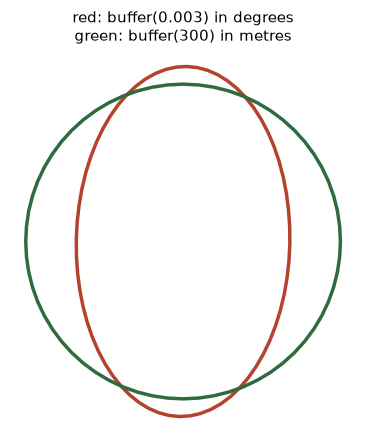

In [ ]:
fig, ax = plt.subplots(figsize=(5, 5))
gpd.GeoSeries([reprojected], crs=25833).plot(ax=ax, facecolor="none",
                                             edgecolor="#B4432E", linewidth=2.5)
gpd.GeoSeries([met_buffer], crs=25833).plot(ax=ax, facecolor="none",
                                            edgecolor="#2E6B3F", linewidth=2.5)
ax.set_title("red: buffer(0.003) in degrees\ngreen: buffer(300) in metres", fontsize=11)
ax.set_aspect("equal"); ax.set_axis_off()
plt.show()

## Choosing the right CRS

1. **What am I doing?** Storing or sharing → keep EPSG:4326. Measuring or mapping → project (UTM).

2. **Where is my data?** A local projected CRS beats a global one. Germany uses UTM zones 32
   and 33; most countries publish a national grid.

In [ ]:
print("Berlin    ->", acc.estimate_utm_crs())

wiesbaden = gpd.GeoSeries(gpd.points_from_xy([8.2416], [50.0826]), crs=4326)
print("Wiesbaden ->", wiesbaden.estimate_utm_crs())


Berlin    -> EPSG:32633
Wiesbaden -> EPSG:32632


## The checklist

Five lines that prevent all of the above.

```python
print(gdf.crs)                  # 1. know what you have
gdf = gdf.to_crs(25833)         # 2. project before measuring  (to_crs, never set_crs)
assert gdf.crs == other.crs     # 3. match layers before joining
# 4. never measure in EPSG:3857
# 5. buffer, area and distance only after step 2
```


⏭ **Next:** Vector Operations: spatial joins, buffers and overlays
